
# **Interpolacija**

Neka su dati čvorovi $x_0, x_1, \ldots, x_n$ i odgovarajuće vrednosti funkcije $f_0, f_1, \ldots, f_n$. **Problem interpolacije** je pronaći polinom $P_n(x)$ stepena $n$ takav da važi:
$$P_n(x_i) = f_i, \quad i = 0, 1, \ldots, n.$$

Takav polinom uvek postoji i jedinstven je, ali postoji više oblika u kojima se može zapisati. Mi ćemo obraditi sledeće:

1. **Lagranžov oblik** — teorijski najelegantniji, dobar za izračunavanje u tački
2. **Njutnov oblik sa podeljenim razlikama** — efikasan kada se čvorovi dodaju postepeno
3. **Njutnov oblik sa konačnim razlikama** — prilagođen ekvidistantnim čvorovima


In [5]:
import numpy as np
import matplotlib.pyplot as plt
import math

---
## 1. Lagranžov interpolacioni polinom


**Lagranžovi bazisni polinomi** definišu se kao:
$$l_i(x) = \prod_{\substack{j=0 \\ j \neq i}}^{n} \frac{x - x_j}{x_i - x_j}, \quad i = 0, 1, \ldots, n,$$
i zadovoljavaju uslov $l_i(x_j) = \delta_{ij}$.

**Lagranžov interpolacioni polinom** je tada:
$$P_n(x) = \sum_{i=0}^{n} f_i \, l_i(x).$$



### Zadatak 1
Isprogramirati metodu `Lagranz_u_tacki(X, F, x)` koja izračunava vrednost Lagranžovog interpolacionog polinoma funkcije $f$ u tački `x`, na osnovu čvorova `X` i vrednosti funkcije $f$ u tim čvorovima `F`.


In [3]:
def Lagranz_u_tacki(X, F, x):
    """
    Izračunava vrednost Lagranžovog interpolacionog polinoma u tački x.

    Ulaz:
        X : niz čvorova interpolacije
        F : niz vrednosti funkcije u čvorovima (F[i] = f(X[i]))
        x : tačka u kojoj se izračunava vrednost polinoma

    Izlaz:
        Vrednost interpolacionog polinoma P_n(x).
    """
    S = 0
    n = len(X)
    for i in range(n):
        P = 1
        for j in range(n):
            if j != i:
                P = P * (x - X[j]) / (X[i] - X[j])
        S = S + P * F[i]
    return S

### Test primer

Koristimo 4 čvora $X = [-2,\; -0.5,\; 0,\; 1.8]$ i vrednosti $F = \sin(X)$, kako bismo interpolacionim polinomom aproksimirali vrednost $\sin(x)$.

Uporedjujemo dobijenu vrednost sa tačnom vrednošću za različite tačke.


In [16]:
x = np.pi / 2
X = np.array([-2, -0.5, 0, 1.8])
F = np.sin(X)

y_interp = Lagranz_u_tacki(X, F, x)
y_tacno  = np.sin(x)

print("Interpolirana vrednost:", y_interp)
print("Tačna vrednost:", y_tacno)
print("Greška:", abs(y_interp - y_tacno))

Interpolirana vrednost: 1.0168379247797128
Tačna vrednost: 1.0
Greška: 0.0168379247797128



### Zadatak 2
Lagranžov polinom možemo zapisati u standardnoj formi:
$$P_n(x) = a_n x^n + a_{n-1} x^{n-1} + \cdots + a_1 x + a_0.$$
Isprogramirati metodu koja računa koeficijente $[a_n, \ldots, a_0]$ pomoću konvolucije polinoma (funkcija `np.convolve` množi polinome) korišćenjem Lagranžovog oblika interpolacionog polinoma.

Potom, koristeći čvorove iz prethodnog test primera i funkciju `np.polyval`, za evaluiranje polinoma, u istom grafičkom prozoru nacrtati:
- interpolacioni polinom $P_n(x)$ na intervalu $[-\pi, \pi]$
- originalnu funkciju $\sin(x)$ na istom intervalu
- čvorove interpolacije

Uočiti kako se polinom ponaša **izvan intervala** koji pokrivaju čvorovi.


In [17]:
def Lagranz_koeficijenti(X, F):
    """
    Računa koeficijente Lagranžovog interpolacionog polinoma
    u obliku pogodnom za numpy.polyval.

    Ulaz:
        X : niz čvorova interpolacije
        F : niz vrednosti funkcije u čvorovima

    Izlaz:
        Niz koeficijenata [a_n, ..., a_1, a_0].
    """
    n = len(X)
    S = np.zeros(n)
    for i in range(n):
        P = 1
        for j in range(n):
            if j != i:
                P = np.convolve(P, np.array([1, -X[j]]) / (X[i] - X[j]))
        S = S + P * F[i]
    return S

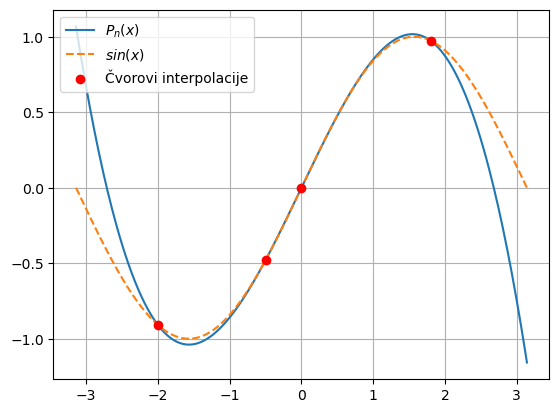

In [18]:
koef = Lagranz_koeficijenti(X, F)

xx = np.linspace(-np.pi, np.pi, 300)

plt.plot(xx, np.polyval(koef, xx), label='$P_n(x)$ ')
plt.plot(xx, np.sin(xx), '--', label='$sin(x)$')
plt.scatter(X, F, color='red', zorder=2, label='Čvorovi interpolacije')
plt.legend()
plt.grid(True)

Šta se dešava ako povećamo broj čvorova? Da li polinom nužno bolje aproksimira funkciju?

### Primer - **Rungeov fenomen**

 Kod ekvidistantnih čvorova na intervalu $[-1, 1]$, povećanje stepena polinoma ne mora da poboljšava aproksimaciju — naprotiv, greška na krajevima intervala može neograničeno rasti. Ovo je demonstrirano u narednoj ćeliji.


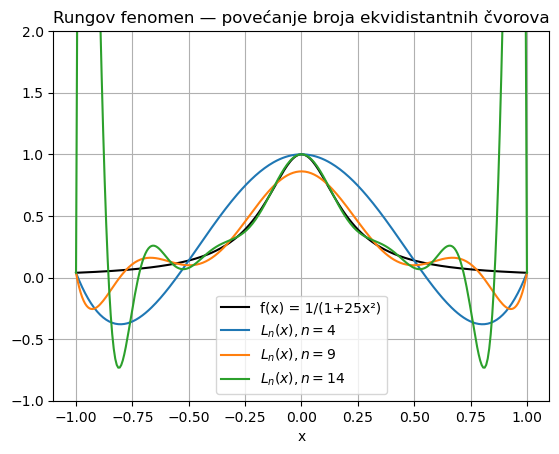

In [23]:
f_runge = lambda x: 1 / (1 + 25 * x**2)

xx = np.linspace(-1, 1,300)
plt.plot(xx, f_runge(xx), 'k-',label='f(x) = 1/(1+25x²)')

for n in [5, 10, 15]:
    X_n = np.linspace(-1, 1, n)
    F_n = f_runge(X_n)
    koef_n = Lagranz_koeficijenti(X_n, F_n)
    plt.plot(xx, np.polyval(koef_n, xx), label=f'$L_n(x), n={n-1}$')

plt.ylim(-1, 2)
plt.xlabel('x')
plt.title('Rungov fenomen — povećanje broja ekvidistantnih čvorova')
plt.legend()
plt.grid(True)
plt.show()

---
## 2. Njutnov interpolacioni polinom sa podeljenim razlikama

**Podeljene razlike** definišu se rekurzivno:
$$f[x_i] = f_i, \qquad f[x_i, \ldots, x_{i+k}] = \frac{f[x_{i+1},\ldots,x_{i+k}] - f[x_i,\ldots,x_{i+k-1}]}{x_{i+k} - x_i}.$$

**Njutnov oblik** interpolacionog polinoma je:
$$P(x) = f[x_0] + f[x_0,x_1](x-x_0) + f[x_0,x_1,x_2](x-x_0)(x-x_1) + \cdots + f[x_0,...,x_n](x-x_0)...(x-x_{n-1}).$$

**Prednost** ovog oblika: dodavanje novog čvora zahteva samo jedan novi sabirak — ne moramo ponovo računati sve od početka.


### Zadatak 3

Isprogramirati metodu `tablica_PR(X, F)` koja konstruiše tablicu podeljenih razlika. Prva kolona tablice sadrži podeljene razlike nultog reda (vrednosti funkcije u čvorovima). Potom isprogramirati metodu `NjutnPR_u_tacki(X, F, x)` koja izračunava vrednost Njutnovog interpolacionog polinoma (sa podeljenim razlikama) u tački `x`.

In [24]:
def tablica_PR(X, F):
    """
    Konstruiše tablicu podeljenih razlika.

    Ulaz:
        X : niz čvorova dužine n (ne moraju biti ekvidistantni)
        F : niz vrednosti funkcije u čvorovima

    Izlaz:
        Kvadratna matrica (n x n) podeljenih razlika.
    """
    n = len(X)
    tablica = np.zeros((n, n))
    tablica[:, 0] = F
    for i in range(1, n):
        brojioci = np.diff(tablica[:n - i + 1, i - 1])
        imenioci = X[i:] - X[:n - i]
        tablica[:n - i, i] = brojioci / imenioci
    return tablica

#drugi način
def tablica2(X,F):
    n = len(X)
    tablica = np.zeros((n, n))
    tablica[:, 0] = F
    for j in range(1, n):
        for i in range(n-j):
            tablica[i,j]=(tablica[i+1,j-1]-tablica[i,j-1])/(X[i+j]-X[i])
       
    return tablica


In [28]:
def NjutnPR_u_tacki(X, F, x):
    """
    Izračunava vrednost Njutnovog interpolacionog polinoma
    (sa podeljenim razlikama) u tački x.

    Ulaz:
        X : niz čvorova interpolacije
        F : niz vrednosti funkcije u čvorovima (F[i] = f(X[i]))
        x : tačka u kojoj se izračunava vrednost polinoma

    Izlaz:
        Vrednost interpolacionog polinoma P_n(x).

    """
    n = len(X)
    tablica = tablica_PR(X, F)
    S = 0
    w = 1
    for i in range(n):
        S = S + tablica[0, i] * w
        w = w * (x - X[i])
    return S

> **Za vežbu:** modifikovati prethodnu metodu tako da vraća sve vrednosti $P_k(x),\,k=0,1,...,n$.

###  Test primer

Dati su čvorovi $X = [0.5, 1, 2, 4]$ i vrednosti $F = 1/X$.  Koristeći prvih $n+1$ čvorova izračunati vrednosti interpolacionih polinoma stepena $n=1,2,3$, u tački $x = 0.8$ i uporediti sa tačnom vrednošću.


In [30]:
X = np.array([0.5, 1, 2, 4])
F = 1 / X
x = 0.8

T = tablica_PR(X, F)
print("\nTablica podeljenih razlika:")
print(np.round(T, 4))

y_tacno  = 1 / x
print(f"Tačna vrednost: 1/x = {y_tacno:.4f}\n")
for n in range (1,4):
  y_interp = NjutnPR_u_tacki(X[:n+1], F[:n+1], x)
  print(f"P_n(3), n={n}: {y_interp:.4f}")
  print(f"R_n(3), n={n}: {abs(y_interp - y_tacno):.2e}\n")



Tablica podeljenih razlika:
[[ 2.    -2.     1.    -0.25 ]
 [ 1.    -0.5    0.125  0.   ]
 [ 0.5   -0.125  0.     0.   ]
 [ 0.25   0.     0.     0.   ]]
Tačna vrednost: 1/x = 1.2500

P_n(3), n=1: 1.4000
R_n(3), n=1: 1.50e-01

P_n(3), n=2: 1.3400
R_n(3), n=2: 9.00e-02

P_n(3), n=3: 1.3220
R_n(3), n=3: 7.20e-02



### Zadatak 4

Isprogramirati metodu koja računa koeficijente $[a_n, \ldots, a_0]$ pomoću konvolucije polinoma korišćenjem Njutnovog oblika interpolacionog polinoma.

Potom, koristeći tablicu iz prethodnog test primera u istom grafičkom prozoru nacrtati:
- interpolacioni polinom $P_n(x)$ na intervalu $[0.5,4]$
- originalnu funkciju $1/x$ na istom intervalu
- interpolacione čvorove


In [ ]:
def NjutnPR_koeficijenti(X, F):
    """
    Računa koeficijente Njutnovog interpolacionog polinoma
    (sa podeljenim razlikama) u standardnom obliku za np.polyval.
    """
    tablica = tablica_PR(X, F)
    n = len(X)
    S = np.zeros(n)
    w = 1
    for i in range(n):
        S[n - i - 1:] = S[n - i - 1:] + tablica[0, i] * w
        w = np.convolve(w, [1, -X[i]])
    return S

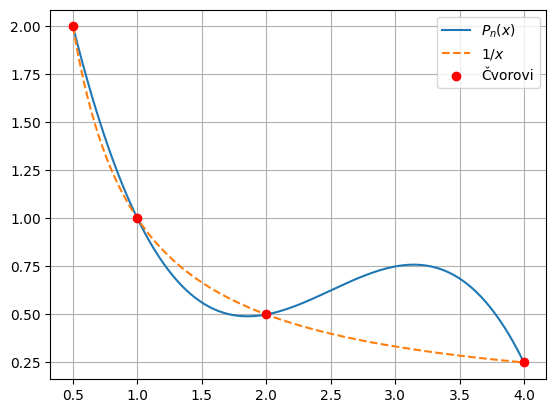

In [ ]:
koef = NjutnPR_koeficijenti(X, F)
xx = np.linspace(0.5, 4, 200)

plt.plot(xx, np.polyval(koef, xx), label='$P_n(x)$')
plt.plot(xx, 1 / xx, '--', label='$1/x$')
plt.scatter(X, F, color='red', zorder=5, label='Čvorovi')
plt.legend()
plt.grid(True)

---
## 3. Njutnov interpolacioni polinom sa konačnim razlikama

Kada su čvorovi **ekvidistantni** ($x_i = x_0 + i\,h$), podeljene razlike se mogu zameniti konačnim razlikama:
$$\Delta^0 f_i = f_i, \qquad \Delta^k f_i = \Delta^{k-1} f_{i+1} - \Delta^{k-1} f_i.$$

Uvođenjem smene $q = \frac{x - x_0}{h}$, dobijamo:

**I Njutnov polinom** (za interpolaciju bliže početku tabele):
$$P_n(x) = P^I_n(q)=f_0+\Delta^1 f_0q+\Delta^2 f_0\frac{q(q-1)}{2!}+...+\Delta^n f_0\frac{q(q-1)...(q-n+1)}{n!}.$$

Uvođenjem smene $q=\frac{x - x_n}{h}$, dobijamo:

**II Njutnov polinom** (za interpolaciju bliže kraju tabele):
$$P_n(x) = P^{II}_n(q)=f_n+\Delta^1 f_{n-1}q+\Delta^2 f_{n-2}\frac{q(q+1)}{2!}+...+\Delta^n f_0\frac{q(q+1)...(q+n-1)}{n!}.$$



### Zadatak 5
Isprogramirati metode `uredi_tablicu(X,F)` i `tablica_PR(X, F)`. Prva metoda proverava da li je `X` ekvidistantan i ukoliko jeste, sortira tablicu tako da čvorovi budu u rastućem poretku, dok druga konstruiše tablicu podeljenih razlika. Takođe isprogramirati metode `NjutnI_u_tacki(X, F, x)` i `NjutnII_u_tacki(X, F, x)` koje izračunavaju vrednost prvog i drugog Njutnovog interpolacionog polinoma sa konačnim razlikama u tački `x`.

In [ ]:


def uredi_tablicu(X, F):
    """
    Sortira čvorove u rastući redosled i proverava ekvidistantnost.
    Zaustavlja izvršavanje ako čvorovi nisu ekvidistantni.
    """
    srt_indeksi = np.argsort(X)
    X = X[srt_indeksi]
    F = F[srt_indeksi]
    diffs = np.diff(X)
    if not np.allclose(diffs, diffs[0]):
        raise ValueError('Greška: elementi iz X nisu ekvidistantni!')
    return X, F

def tablica_KR(F):
    """
    Gradi tablicu konačnih razlika za ekvidistantne čvorove.

    Ulaz:
        F : niz vrednosti funkcije u čvorovima

    Izlaz:
        Kvadratna matrica (n x n) konačnih razlika.
    """
    n = len(F)
    tablica = np.zeros((n, n))
    tablica[:, 0] = F
    for i in range(1, n):
        tablica[:n - i, i] = np.diff(tablica[:n - i + 1, i - 1])
    return tablica

In [ ]:
def NjutnI_u_tacki(X, F, x):
    """
    Izračunava vrednost I Njutnovog interpolacionog polinoma
    (sa konačnim razlikama) u tački x.
    """
    X, F = uredi_tablicu(X, F)
    tablica = tablica_KR(F)
    n = len(X)
    h = X[1] - X[0]
    q = (x - X[0]) / h
    S = 0
    w = 1
    for i in range(n):
        S = S + tablica[0, i] * w / math.factorial(i)
        w = w * (q - i)
    return S


def NjutnII_u_tacki(X, F, x):
    """
    Izračunava vrednost II Njutnovog interpolacionog polinoma
    (sa konačnim razlikama) u tački x.
    """
    X, F = uredi_tablicu(X, F)
    tablica = tablica_KR(F)
    n = len(X)
    h = X[1] - X[0]
    q = (x - X[n - 1]) / h
    S = 0
    w = 1
    for i in range(n):
        S = S + tablica[n - i - 1, i] * w / math.factorial(i)
        w = w * (q + i)
    return S

### Test primer

Neka vektor $X$ sadrži 6 ekvidistantnih čvorova na segmentu $[0,3]$, i $F=\text{exp}(X)$. Odrediti i ispisati tablicu konačnih razlika, a zatim izračunati i uporediti vrednosti $I$ i $II$ Njutnovog interpolacionog polinoma u različitim delovima tablice.


In [ ]:
X = np.linspace(0,3,6)
F = np.exp(X)

print("\nTablica konačnih razlika:")
X, F = uredi_tablicu(X, F)
T = tablica_KR(F)
print(np.round(T, 4))

x=1.35
y1 = NjutnI_u_tacki(X, F, x)
y2 = NjutnII_u_tacki(X, F, x)
print(f"\nI Njutnov polinom: P(x)={y1:.8f}")
print(f"II Njutnov polinom: P(x)={y2:.8f}")
print(f"Razlika: {abs(y1 - y2):.4e}")


,Tablica konačnih razlika:
,[[ 1.      0.8221  0.6759  0.5557  0.4568  0.3756]
, [ 1.8221  1.498   1.2315  1.0125  0.8324  0.    ]
, [ 3.3201  2.7295  2.244   1.8448  0.      0.    ]
, [ 6.0496  4.9735  4.0888  0.      0.      0.    ]
, [11.0232  9.0624  0.      0.      0.      0.    ]
, [20.0855  0.      0.      0.      0.      0.    ]]
,
,I Njutnov polinom: P(x)=3.85818898
,II Njutnov polinom: P(x)=3.85818898
,Razlika: 2.6645e-15


---
## 4. Inverzna interpolacija

Neka je funkcija $f$ zadata tablično. Zanima nas možemo li za dato $y$  približno odrediti $x$ za koje važi $f(x) = y$.

Jedan način na koji se može pristupiti ovom problemu podrazumeva zamena uloga između čvorova i vrednosti funkcije u njima $X \leftrightarrow F$. Ovaj pristup koji odgovara interpolaciji funkcije $f^{-1}(y)$ ima smisla samo ukoliko je $f$ monotona funkcija. U tom slučaju možemo primeniti Lagranžovu interpolaciju na tablicu $[F, X]$ i u tački $y$ dobiti aproksimaciju tražene vrednosti $x$.


### Zadatak 6

Koristeći čvorove $X = [2, 3, 5]$ i vrednosti $F = \sin(X)$, inverznom interpolacijom aproksimirati $x$ takvo da $\sin(x) = 0$.

Nacrtajte na istom grafiku funkciju $\sin(x)$, interpolacioni polinom tablice $[X, F]$ i inverzni polinom tablice $[F, X]$. Proveriti šta se dešava ukoliko interpolirana funkcija nije monotona na posmatranom segmentu.


Inverzna interpolacija: x ≈ 3.219172
,Tačna vrednost π = 3.141593
,Greška = 7.76e-02


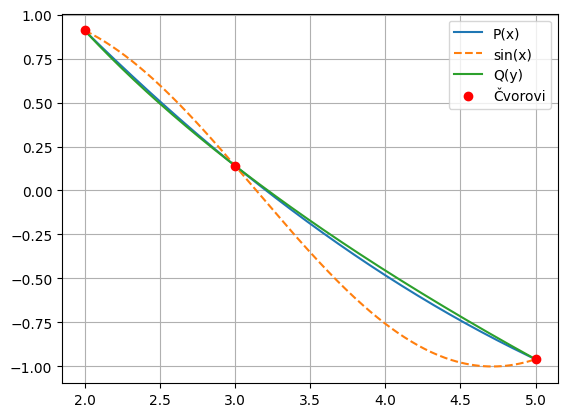

In [ ]:
X = np.array([2, 3, 5])
# X = np.array([1,2,3]) # primer šta se dešava kada fcja. nije monotona
F = np.sin(X)

x= Lagranz_u_tacki(F, X, 0)
print(f"Inverzna interpolacija: x ≈ {x:.6f}")
print(f"Tačna vrednost π = {np.pi:.6f}")
print(f"Greška = {abs(x - np.pi):.2e}")

xx = np.linspace(min(X), max(X), 200)
yy = np.linspace(min(F), max(F), 200)
koef_dir = Lagranz_koeficijenti(X, F)
koef_inv = Lagranz_koeficijenti(F, X)

plt.plot(xx, np.polyval(koef_dir, xx), label='P(x)')
plt.plot(xx, np.sin(xx), '--', label='sin(x)')
plt.plot(np.polyval(koef_inv, yy),yy, label='Q(y)')
plt.scatter(X, F, color='red', zorder=5, label='Čvorovi')
plt.legend();
plt.grid(True)


Drugi način na koji se može aproksimirati $x$ takvo da je $f(x)=y$ jeste interpolacijom funkcije $f$ polinomom $P(x)$ i rešavanjem nelinearne jednačine $P(x)=y$.

Ovaj pristup je primenljiv i kada $f$ nije monotona, a koraci su sledeći:
1. **Lokalizacija:** naći interval $[x_i, x_{i+1}]$ gde $f(x) - y$ menja znak.
2. **Lokalna interpolacija:** izgraditi interpolacioni polinom na čvorovima oko tog intervala.
3. **Rešiti** jednačinu $P(x) = y$ i odabrati koren u lokalizovanom intervalu.

### Zadatak 7

Isprogramirati metodu `inverzna_interpolacija(X, F, y)` koja konstruiše interpolacioni polinom $P(x)$ stepena 3 oko intervala gde $f(x)-y$ menja znak i određuje rešenje jednačine $P(x) = y$ koje pripada lokalizovanom intervalu.

Za rešavanje jednačine koristiti ugrađenu funkciju `np.roots()` za određivanje nula polinoma.



Potom, proceniti vrednost $f^{-1}(1.1)$ za tablično zadatu funkciju $f$:
|$i$|0|1|2|3|4|
|----|----|--------|-----|-----|-----|
| $x_i$ | $0.2$ | $0.5$ | $0.8$ | $1.2$ | $2.5$ |
| $f_i$ | $5$ | $2$ | $1.25$ | $0.83$ | $0.4$ |

($f(x)=1/x$)



In [ ]:
def lokalizacija(X, F, y):
    """
    Pronalazi indeks i takav da f(X[i]) i f(X[i+1]) okružuju vrednost y.
    """
    F_mod = F - y
    n = len(X)
    for i in range(n - 1):
        if F_mod[i] * F_mod[i + 1] < 0:
            return i
    raise ValueError('Greška: ne postoji interval koji je kandidat za f(x) = y.')

def inverzna_interpolacija(X, F, y):
    """
    Inverzna interpolacija rešavanjem nelinearne jednačine.
    Lokalizuje interval promene znaka, interpoluje polinom stepena 3
    na 4 susedna čvora i rešava jednačinu P(x) = y.

    Ulaz:
        X : niz čvorova
        F : niz vrednosti funkcije
        y : tražena vrednost

    Izlaz:
        Aproksimaciju x takve da f(x) ≈ y.
    """
    srt_indeksi = np.argsort(X)
    X = X[srt_indeksi]
    F = F[srt_indeksi]
    n = len(X)
    i = lokalizacija(X, F, y)
    koef = Lagranz_koeficijenti(X[i-1:i+3], F[i-1:i+3])
    koef[-1]=koef[-1]-y
    koreni=np.roots(koef)
    for koren in koreni:
      if koren>X[i] and koren<X[i+1]:
        return np.real(koren)

In [ ]:
X = np.array([0.2,0.5, 0.8, 1.2, 2.5])
F = np.round(1/X,2)
y = 1.1

x = inverzna_interpolacija(X, F, y)
x_tacno = 1 / y
print(f"Inverzna interpolacija: x ≈ {x:.6f}")
print(f"Tačna vrednost: {x_tacno:.6f}")
print(f"Greška: {abs(x - x_tacno):.2e}")

Inverzna interpolacija: x ≈ 0.894758
,Tačna vrednost: 0.909091
,Greška: 1.43e-02


---
## 5. Aproksimacija izvoda interpolacionim polinomom


Određivanjem interpolacionog polinoma $P(x)$ dobijamo i aproksimaciju izvoda funkcije $f$:
$$f^{(k)}(x) \approx P^{(k)}(x).$$

Alternativno, za procenu prvog izvoda na tablici sa ekvidistantnim čvorovima, mogu se koristiti i  podeljene razlike:
$$f'(x_i) \approx \frac{f(x_{i+1}) - f(x_{i-1})}{2h}.$$


### Zadatak 8

Isprogramirati metodu `uporedi_izvod(f, f1, a, b, n)`, koja za zadatu funkciju `f` određuje izvod njenog interpolacionong polinom konstruisanog na segmentu [`a`,`b`], korišćenjem `n` ekvidistantnih čvorova. Metoda potom grafički upoređuje ovu aproksimaciju izvoda sa tačnim izvodom `f1` i aproksimacijama izvoda u čvorovima određenim podeljenim razlikama.

Za određivanje izvoda polinoma koristiti ugrađenu metodu `np.polyder(P, k)`, koja izračunava koeficijente `k`-tog izvoda polinoma zadatog koeficijentima `P`.

In [ ]:
def uporedi_izvod(f, f1, a, b, n):
    """
    Grafički poredi tačan prvi izvod f'(x), aproksimaciju P'(x) i
    vrednosti podeljenih razlika u unutrašnjim čvorovima.

    Ulaz:
        f     : originalna funkcija (lambda)
        f1    : tačan prvi izvod (lambda)
        a, b  : granice intervala
        n     : broj čvorova interpolacije
    """
    X = np.linspace(a, b, n)
    F = f(X)
    P = Lagranz_koeficijenti(X, F)
    P1 = np.polyder(P,1)
    xx = np.linspace(a, b, 300)
    h  = X[1] - X[0]
    pr = (F[2:] - F[:-2]) / (2 * h)

    plt.plot(xx, f1(xx), 'k-', linewidth=2, label="f'(x)")
    plt.plot(xx, np.polyval(P1, xx), 'b--', label="P'(x)")
    plt.scatter(X[1:-1], pr, color='red', zorder=5, label='Podeljene razlike')
    plt.legend()
    plt.grid(True)


### Test primer
Primenom metode iz zadatka 8 na funkciju $f(x)=\sin(x^2)-x$ dobijamo sledeću sliku.

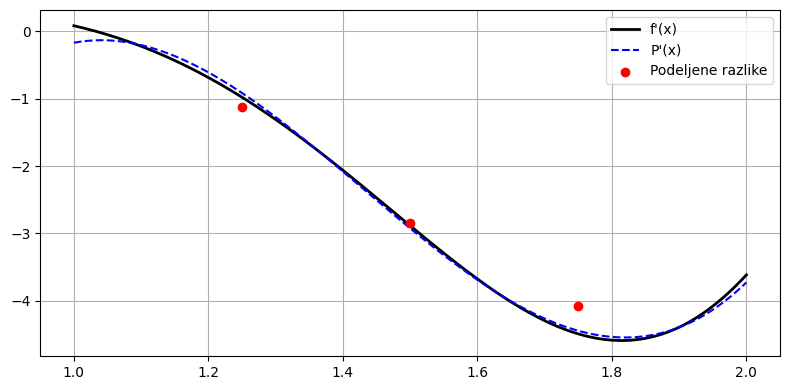

In [ ]:
f  = lambda x: np.sin(x**2) - x
f1 = lambda x: 2*np.cos(x**2)*x - 1

plt.figure(figsize=(8, 4))
uporedi_izvod(f, f1, 1, 2, 5)
plt.tight_layout()
plt.show()

### Zadatak 9

Isprogramirati metodu `izvodi_viseg_reda(f_sym, a, b, n)` koja crtata 2×2 grafik koji poredi $f^{(k)}(x)$ i $P^{(k)}(x)$ za $k = 0, 1, 2, 3$, gde je $P(x)$ kubni polinom nad $n = 4$ ekvidistantna čvora na intervalu $[1, 3]$.

Tačne vrednosti viših izvoda odrediti simboličkim diferenciranjem pomoću biblioteke `sympy`.


In [ ]:
import sympy as sp


def izvodi_viseg_reda(f_sym, a, b, n):
    """
    Crta 2x2 grafik: f i prva 3 izvoda, svaki put uporedjujući
    tačnu vrednost (sympy) sa aproksimacijom (Lagranžov polinom).

    Parametri:
        f_sym : funkcija u sympy obliku
        a, b  : interval
        n     : broj čvorova interpolacije
    """
    x_sym = sp.Symbol('x')
    f_num = sp.lambdify(x_sym, f_sym, 'numpy')

    X = np.linspace(a, b, n)
    F = f_num(X)
    P = Lagranz_koeficijenti(X, F)
    xx = np.linspace(a, b, 300)

    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    oznake = ['f(x)', "f'(x)", "f''(x)", "f'''(x)"]
    f_iter = f_sym

    for i in range(4):
        ax = axes[i // 2][i % 2]
        f_iter_num = sp.lambdify(x_sym, f_iter, 'numpy')
        ax.plot(xx, f_iter_num(xx), 'k-', label=f'{oznake[i]}')
        ax.plot(xx, np.polyval(np.polyder(P, i), xx), 'b--', label=f'P^({i})(x)')
        ax.set_title(oznake[i])
        ax.legend()
        ax.grid(True)
        f_iter = sp.diff(f_iter, x_sym)


### Test primer

Primenom metode iz zadatka 9 na funkciju $f(x) = \sin(\ln^2(x))$ dobijamo sledeću sliku.
  

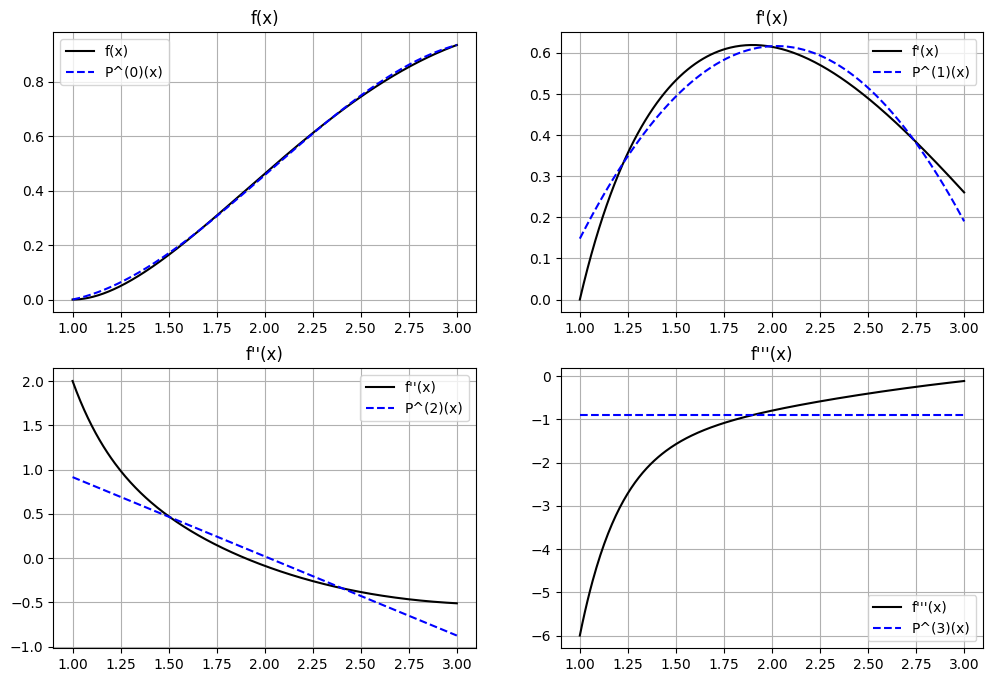

In [ ]:
x_sym = sp.Symbol('x')
f_sym = sp.sin(sp.log(x_sym)**2)
a = 1
b = 3
n = 4
izvodi_viseg_reda(f_sym,a,b,n)